# ⚔️ Notebook 3: Support Vector Machine (LinearSVC)
**Project**: Sentiment Analysis on YouTube Comments  
**Model**: Linear Support Vector Classifier (`LinearSVC`)  
**Feature Engineering**: TF-IDF Vectorization (`max_features=10000`, Unigrams & Bigrams)  
**Objective**: Leverage high-dimensional margin maximization to classify YouTube comments sentiment and inspect top feature coefficients for interpretability.


In [1]:
# Standard Imports
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

RANDOM_STATE = 42
print("Imports completed successfully!")


Imports completed successfully!


---
## 1. Data Preparation & Stratified Split
Loading data, establishing label mappings, and performing a reproducible 80/20 stratified split.


In [2]:
KAGGLE_PATH = "/kaggle/input/datasets/amaanpoonawala/youtube-comments-sentiment-dataset/youtube_comments_cleaned.csv"
LOCAL_PATH = "youtube_comments_cleaned.csv"

data_path = KAGGLE_PATH if os.path.exists(KAGGLE_PATH) else LOCAL_PATH
df = pd.read_csv(data_path).dropna(subset=['CommentText', 'Sentiment']).reset_index(drop=True)
df['CommentText'] = df['CommentText'].astype(str)

label_mapping = {'Negative': 0, 'Neutral': 1, 'Positive': 2}
reverse_mapping = {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
df['label'] = df['Sentiment'].map(label_mapping)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df['CommentText'],
    df['label'],
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df['label']
)

print(f"Train samples: {len(X_train_raw):,}, Test samples: {len(X_test_raw):,}")


Train samples: 825,780, Test samples: 206,445


---
## 2. Feature Extraction (TF-IDF Vectorization)
Extracting up to 10,000 unigram and bigram TF-IDF features.


In [3]:
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=10000,
    stop_words='english'
)

X_train_tfidf = vectorizer.fit_transform(X_train_raw)
X_test_tfidf = vectorizer.transform(X_test_raw)

print(f"TF-IDF Feature Space Dimensions: {X_train_tfidf.shape[1]}")


TF-IDF Feature Space Dimensions: 10000


---
## 3. Model Training: LinearSVC
Training a `LinearSVC` model designed for efficient linear margin separation in text classification.


In [4]:
svm_model = LinearSVC(C=1.0, random_state=RANDOM_STATE, max_iter=2000)
svm_model.fit(X_train_tfidf, y_train)

print("LinearSVC Model Training Complete!")


LinearSVC Model Training Complete!


---
## 4. Evaluation & Confusion Matrix
Evaluating model performance on test set.


=== Support Vector Machine (LinearSVC) Test Accuracy: 66.06% ===

Classification Report:
              precision    recall  f1-score   support

    Negative       0.66      0.66      0.66     69215
     Neutral       0.59      0.65      0.62     68567
    Positive       0.74      0.67      0.70     68663

    accuracy                           0.66    206445
   macro avg       0.67      0.66      0.66    206445
weighted avg       0.67      0.66      0.66    206445



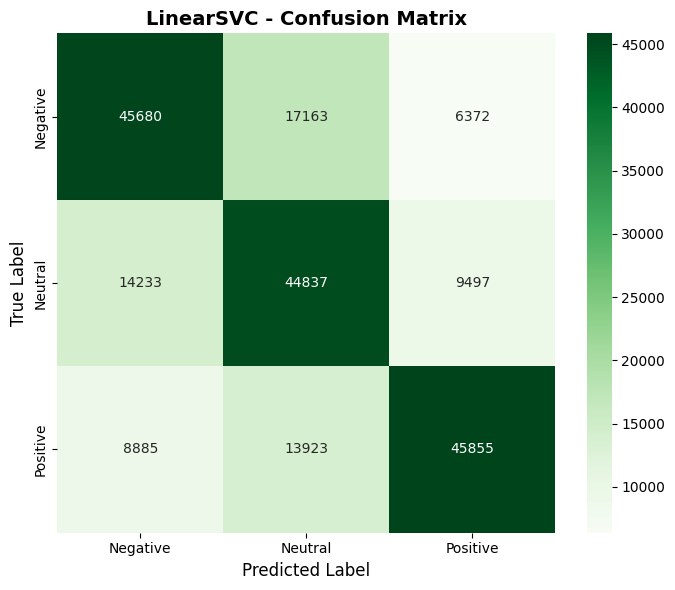

In [5]:
y_pred = svm_model.predict(X_test_tfidf)

acc = accuracy_score(y_test, y_pred)
print(f"=== Support Vector Machine (LinearSVC) Test Accuracy: {acc * 100:.2f}% ===\n")

class_names = ['Negative', 'Neutral', 'Positive']
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names)
plt.title('LinearSVC - Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()


---
## 5. Model Interpretability: Most Informative Words per Sentiment Class
Extracting top feature coefficients from the linear decision boundaries.


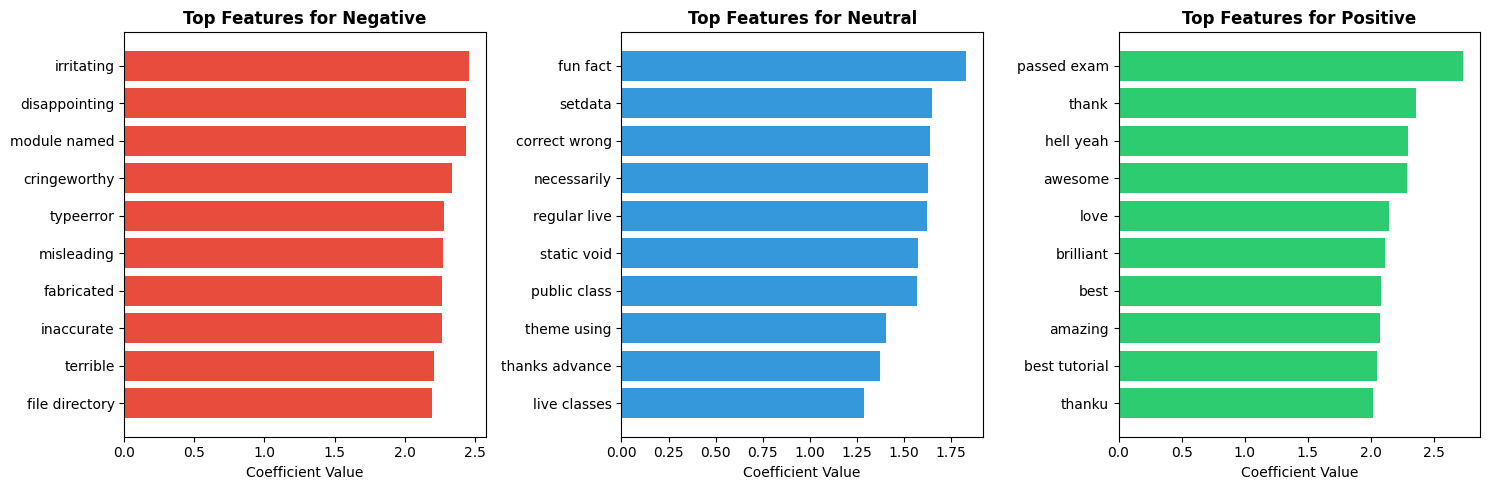

In [6]:
feature_names = np.array(vectorizer.get_feature_names_out())

plt.figure(figsize=(15, 5))
for i, class_name in enumerate(class_names):
    top10 = np.argsort(svm_model.coef_[i])[-10:]
    plt.subplot(1, 3, i + 1)
    plt.barh(feature_names[top10], svm_model.coef_[i][top10], color=['#e74c3c', '#3498db', '#2ecc71'][i])
    plt.title(f'Top Features for {class_name}', fontsize=12, fontweight='bold')
    plt.xlabel('Coefficient Value')

plt.tight_layout()
plt.show()
